# ProductPulse — Data Cleaning & Generation

Turns the real **IBM Telco Customer Churn** dataset into ProductPulse's four
Postgres tables (`users`, `events`, `subscriptions`, `payments`).

**Why this isn't pure fabrication:** no public dataset pairs row-level product
usage with real subscription billing for the same users. So this notebook keeps
everything that genuinely exists in the real data (tenure, monthly/total
charges, contract economics, the churn label) and only generates what has no
public source — session-level product events, and a small pool of trial users
who never converted (Telco only contains people who were *already* paying
customers, so a funnel needs a top that Telco alone can't provide).

Full column-by-column source mapping and the reasoning behind every constant
below lives in [`docs/data_dictionary.md`](../docs/data_dictionary.md) — this
notebook implements that spec.


## Setup

In [1]:
import os
import time

import numpy as np
import pandas as pd

t0 = time.time()

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

# --- Reference constants (see docs/data_dictionary.md for the reasoning) ---
SNAPSHOT_DATE = pd.Timestamp('2026-08-31')   # the fictional "as of" date
TRIAL_LENGTH_DAYS = 14
NON_CONVERTER_RATE = 0.30                    # synthetic trial drop-offs, as a
                                              # fraction of the real (already-
                                              # paying) Telco base — gives an
                                              # overall trial->paid conversion
                                              # of roughly 77%, plausible for a
                                              # guided/sales-assisted B2B trial

RAW_PATH = '../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv'
OUT_DIR = '../data/processed'

# --- Synthetic attribute catalogs ---
COUNTRIES = ['United States', 'United Kingdom', 'India', 'Canada', 'Australia',
             'Germany', 'France', 'Brazil', 'Netherlands', 'Singapore']
COUNTRY_WEIGHTS = [0.42, 0.12, 0.10, 0.08, 0.06, 0.06, 0.05, 0.04, 0.04, 0.03]

CHANNELS = ['Organic Search', 'Paid Search', 'Paid Social', 'Referral', 'Partner', 'Email']
# Mild, documented skew: users who end up churning were sourced a little more
# from paid channels; users who stay active a little more from organic/referral.
CHANNEL_WEIGHTS_CHURNED = [0.22, 0.27, 0.23, 0.10, 0.10, 0.08]
CHANNEL_WEIGHTS_ACTIVE  = [0.32, 0.18, 0.14, 0.18, 0.10, 0.08]

FEATURES = ['Dashboard', 'Reports', 'Integrations', 'TeamManagement', 'API',
            'Notifications', 'Exports', 'Search', 'Billing', 'Settings']
FEATURE_WEIGHTS = [0.24, 0.20, 0.12, 0.10, 0.09, 0.08, 0.06, 0.06, 0.03, 0.02]  # power-law-ish popularity

# Sessions/week by plan tier — deliberately modest. Full derivation in the
# events section below covers each user's ENTIRE tenure (not a trailing
# window — see the note there on why), so even a moderate rate adds up fast
# across years of history.
PLAN_BASE_SESSIONS_PER_WEEK = {'Basic': 0.35, 'Pro': 0.7, 'Enterprise': 1.2}


## Step 1 — Load and clean the real Telco data

The one documented data-quality issue in this dataset: 11 customers with
`tenure == 0` have a blank `TotalCharges` (brand new, no completed billing
cycle yet). That's the *correct* real value, not bad data — `errors='coerce'`
turns the blank into `NaN`, and `fillna(0.0)` makes it explicit.


In [2]:
raw = pd.read_csv(RAW_PATH)
raw['TotalCharges'] = pd.to_numeric(raw['TotalCharges'], errors='coerce').fillna(0.0)
assert raw['customerID'].is_unique, "duplicate customerID in source data"

n_real = len(raw)
print(f"Loaded {n_real} real customers, {raw.shape[1]} columns")
raw.head()


Loaded 7043 real customers, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2 — Build `users` from real signups

Telco has no dates — only `tenure` in whole months as of the snapshot. We
recover a `signup_date` by walking `tenure` months back from `SNAPSHOT_DATE`,
plus a few days of random jitter so signups don't all land on the same
day-of-month (a real artifact-avoidance touch, not noise that affects tenure).
`country` and `acquisition_channel` have no real-data counterpart, so they're
sampled from realistic, documented distributions.


In [3]:
signup_base = raw['tenure'].apply(lambda m: SNAPSHOT_DATE - pd.DateOffset(months=int(m)))
jitter = rng.integers(-10, 11, size=n_real)
real_signup_date = (signup_base + pd.to_timedelta(jitter, unit='D')).clip(upper=SNAPSHOT_DATE)

country_real = rng.choice(COUNTRIES, size=n_real, p=COUNTRY_WEIGHTS)
channel_if_churned = rng.choice(CHANNELS, size=n_real, p=CHANNEL_WEIGHTS_CHURNED)
channel_if_active  = rng.choice(CHANNELS, size=n_real, p=CHANNEL_WEIGHTS_ACTIVE)
is_churn_real = (raw['Churn'].values == 'Yes')
channel_real = np.where(is_churn_real, channel_if_churned, channel_if_active)

users_real = pd.DataFrame({
    'user_id': raw['customerID'].values,
    'signup_date': real_signup_date.dt.date,
    'country': country_real,
    'acquisition_channel': channel_real,
})
users_real.head()


,user_id,signup_date,country,acquisition_channel
0,7590-VHVEG,2026-07-22,United States,Referral
1,5575-GNVDE,2023-11-06,United States,Paid Search
2,3668-QPYBK,2026-07-03,United Kingdom,Partner
3,7795-CFOCW,2022-11-29,United Kingdom,Paid Social
4,9237-HQITU,2026-06-29,United States,Email


## Step 3 — Add a synthetic non-converting trial pool

Telco is, by construction, 100% already-paying customers — it has no record of
anyone who signed up and *didn't* convert. Without adding some, our "trial →
paid" funnel would be a meaningless 100%. We add synthetic trial-only users
sized as `NON_CONVERTER_RATE` of the real base, with `signup_date`s bootstrap-
sampled from the real signup-date distribution (so synthetic signup volume
tracks the real seasonal pattern instead of being flat/uniform) plus their own
jitter. IDs follow the same `NNNN-LLLLL` shape as real Telco IDs so the table
reads as one consistent population.


In [4]:
n_nc = int(round(n_real * NON_CONVERTER_RATE))

def gen_synthetic_ids(existing, n, rng):
    letters = np.array(list('ABCDEFGHIJKLMNOPQRSTUVWXYZ'))
    ids = set()
    while len(ids) < n:
        need = n - len(ids)
        digits = rng.integers(1000, 10000, size=need)
        suffixes = [''.join(rng.choice(letters, size=5)) for _ in range(need)]
        candidates = {f"{d}-{s}" for d, s in zip(digits, suffixes)}
        ids |= (candidates - existing)
    return list(ids)[:n]

existing_ids = set(raw['customerID'])
nc_ids = gen_synthetic_ids(existing_ids, n_nc, rng)

base_idx = rng.integers(0, n_real, size=n_nc)
nc_base_dates = real_signup_date.iloc[base_idx].reset_index(drop=True)
nc_jitter = rng.integers(-5, 6, size=n_nc)
nc_signup_date = (nc_base_dates + pd.to_timedelta(nc_jitter, unit='D')).clip(upper=SNAPSHOT_DATE)

country_nc = rng.choice(COUNTRIES, size=n_nc, p=COUNTRY_WEIGHTS)
channel_nc = rng.choice(CHANNELS, size=n_nc, p=CHANNEL_WEIGHTS_CHURNED)  # never-converted -> "churned" cohort

users_nc = pd.DataFrame({
    'user_id': nc_ids,
    'signup_date': nc_signup_date.dt.date,
    'country': country_nc,
    'acquisition_channel': channel_nc,
})

users = pd.concat([users_real, users_nc], ignore_index=True)
print(f"{n_real} real + {n_nc} synthetic non-converters = {len(users)} total users")
print(f"implied trial->paid conversion: {n_real/len(users):.1%}")


7043 real + 2113 synthetic non-converters = 9156 total users
implied trial->paid conversion: 76.9%


## Step 4 — Build `subscriptions`

In [5]:
# plan tier: tercile of the real MonthlyCharges — grounded in real economics,
# not an arbitrary label
q1, q2 = raw['MonthlyCharges'].quantile([1/3, 2/3])

def plan_from_charge(x):
    if x <= q1:
        return 'Basic'
    if x <= q2:
        return 'Pro'
    return 'Enterprise'

plan_real = raw['MonthlyCharges'].apply(plan_from_charge).values
status_real = np.where(is_churn_real, 'churned', 'active')     # real Churn flag, direct mapping
trial_start_real = real_signup_date.dt.date
paid_date_real_ts = real_signup_date + pd.to_timedelta(TRIAL_LENGTH_DAYS, unit='D')
paid_date_real = paid_date_real_ts.dt.date

subs_real = pd.DataFrame({
    'user_id': raw['customerID'].values,
    'plan': plan_real,
    'status': status_real,
    'trial_start': trial_start_real,
    'paid_date': paid_date_real,
})

# Non-converters: skew toward Basic (price-sensitive prospects drop off more
# often), status is always 'churned', paid_date stays NULL — that NULL is how
# downstream SQL tells "dropped out during trial" apart from "paid, then churned".
NC_PLAN_WEIGHTS = [0.55, 0.32, 0.13]
plan_nc = rng.choice(['Basic', 'Pro', 'Enterprise'], size=n_nc, p=NC_PLAN_WEIGHTS)

subs_nc = pd.DataFrame({
    'user_id': nc_ids,
    'plan': plan_nc,
    'status': 'churned',
    'trial_start': nc_signup_date.dt.date,
    'paid_date': pd.NaT,
})

subscriptions = pd.concat([subs_real, subs_nc], ignore_index=True)
subscriptions.groupby(['status'])['paid_date'].agg(users='count', converted='count')


,users,converted
status,,
active,5174,5174
churned,1869,1869


## Step 5 — Build `payments`, then QA it against the real data

One payment row per elapsed billing month, using the real `tenure` (Telco's
own definition is literally "months billed") and the real `MonthlyCharges`.
That gives us a natural, free QA check: summing reconstructed payments per
user should track the real `TotalCharges` column closely.


In [6]:
pay_records = []
pid = 1
for cid, tenure, charge, pdate in zip(raw['customerID'].values, raw['tenure'].values,
                                       raw['MonthlyCharges'].values, paid_date_real_ts):
    n_pay = max(int(tenure), 0)
    for i in range(n_pay):
        pay_date = pdate + pd.DateOffset(months=i)
        if pay_date > SNAPSHOT_DATE:
            break
        pay_records.append((pid, cid, round(float(charge), 2), pay_date.date()))
        pid += 1

payments = pd.DataFrame(pay_records, columns=['payment_id', 'user_id', 'amount', 'payment_date'])
print(f"{len(payments)} payment rows for {payments['user_id'].nunique()} paying users")


227990 payment rows for 7032 paying users


QA — reconstructed vs. real TotalCharges per user
correlation: 0.9996
count    7043.000000
mean       45.018735
std        49.892509
min         0.000000
25%         9.350000
50%        28.600000
75%        63.625000
max       373.250000
dtype: float64


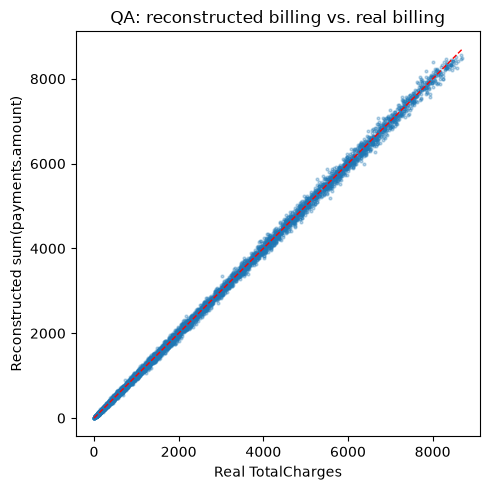

In [7]:
import matplotlib.pyplot as plt

recon = payments.groupby('user_id')['amount'].sum().reindex(raw['customerID']).fillna(0.0).values
qa = pd.DataFrame({'real_total': raw['TotalCharges'].values, 'reconstructed_total': recon})

print("QA — reconstructed vs. real TotalCharges per user")
print(f"correlation: {qa['real_total'].corr(qa['reconstructed_total']):.4f}")
print((qa['real_total'] - qa['reconstructed_total']).abs().describe())

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(qa['real_total'], qa['reconstructed_total'], s=4, alpha=0.3)
ax.plot([0, qa['real_total'].max()], [0, qa['real_total'].max()], 'r--', linewidth=1)
ax.set_xlabel('Real TotalCharges')
ax.set_ylabel('Reconstructed sum(payments.amount)')
ax.set_title('QA: reconstructed billing vs. real billing')
plt.tight_layout()
plt.show()


## Step 6 — Build `events` (the calibrated synthetic layer)

Each user gets a per-week session count drawn from a Poisson process, with a
rate that depends on their plan tier and their own random engagement level.
Churned users (paid-then-left, or never-converted) get a **decay** in their
final three weeks — engagement tapering off before someone cancels is a real,
well-documented pattern, and it's exactly the kind of leading indicator the
churn model in Module 4 will want to pick up on.

**Important scoping choice:** events are generated across each user's *entire*
tenure — not clipped to a trailing calendar window. An earlier version of this
notebook clipped to the trailing 15 months, which silently deleted the
early-lifecycle events that day-7/day-30 retention and cohort analysis depend
on for any cohort older than that window. Full-tenure generation costs more
rows (~3M) but keeps every cohort's onboarding period intact.


In [8]:
def compute_effective_end(paid_ts, tenure, is_churn):
    """Last date this user was active: churn date if they left, else the snapshot."""
    if is_churn:
        end = paid_ts + pd.DateOffset(months=int(tenure))
        return min(end, SNAPSHOT_DATE)
    return SNAPSHOT_DATE

real_effective_end = pd.Series([
    compute_effective_end(pdate, tenure, churn)
    for pdate, tenure, churn in zip(paid_date_real_ts, raw['tenure'].values, is_churn_real)
])

# non-converters churn somewhere inside their 14-day trial
nc_drop_days = rng.integers(1, TRIAL_LENGTH_DAYS + 1, size=n_nc)
nc_effective_end = (nc_signup_date + pd.to_timedelta(nc_drop_days, unit='D')).clip(upper=SNAPSHOT_DATE)

event_basis = pd.concat([
    pd.DataFrame({
        'user_id': raw['customerID'].values,
        'window_start': real_signup_date.values,
        'window_end': real_effective_end.values,
        'plan': plan_real,
        'is_churn': is_churn_real,
    }),
    pd.DataFrame({
        'user_id': nc_ids,
        'window_start': nc_signup_date.values,
        'window_end': nc_effective_end.values,
        'plan': plan_nc,
        'is_churn': True,
    }),
], ignore_index=True)

event_basis = event_basis[event_basis['window_start'] < event_basis['window_end']].reset_index(drop=True)
print(f"{len(event_basis)}/{len(users)} users have a usable activity window for event generation")


9147/9156 users have a usable activity window for event generation


In [9]:
# Business-hours-weighted hour-of-day (people mostly use a B2B tool 8am-6pm)
hours = np.arange(24)
hour_p = np.where((hours >= 8) & (hours <= 18), 3.0, 0.3)
hour_p = hour_p / hour_p.sum()

event_rows = []
eid = 1
for row in event_basis.itertuples(index=False):
    uid = row.user_id
    start = pd.Timestamp(row.window_start)
    end = pd.Timestamp(row.window_end)
    base_rate = PLAN_BASE_SESSIONS_PER_WEEK[row.plan]
    indiv_mult = rng.lognormal(mean=0, sigma=0.4)   # individual engagement variation
    total_days = (end - start).days
    if total_days <= 0:
        continue
    n_weeks = max(int(np.ceil(total_days / 7)), 1)
    session_counter = 0
    for w in range(n_weeks):
        week_start = start + pd.Timedelta(days=7 * w)
        week_end = min(week_start + pd.Timedelta(days=7), end)
        if week_start >= week_end:
            continue
        rate = base_rate * indiv_mult
        if row.is_churn:
            weeks_from_end = (end - week_end).days / 7.0
            if weeks_from_end <= 3:
                rate *= 0.2 + 0.8 * max(weeks_from_end, 0) / 3.0   # taper toward churn
        n_sessions = rng.poisson(lam=max(rate, 0.01))
        if n_sessions == 0:
            continue
        days_span = max((week_end - week_start).days, 1)
        session_days = rng.integers(0, days_span, size=n_sessions)
        for d in session_days:
            session_counter += 1
            session_id = f"{uid}_S{session_counter:04d}"
            day = week_start + pd.Timedelta(days=int(d))
            hour = rng.choice(hours, p=hour_p)
            minute = rng.integers(0, 60)
            ts = day + pd.Timedelta(hours=int(hour), minutes=int(minute))
            event_rows.append((eid, uid, 'login', None, ts, session_id)); eid += 1
            n_feat = rng.integers(1, 5)
            for j, feat in enumerate(rng.choice(FEATURES, size=n_feat, p=FEATURE_WEIGHTS)):
                ts2 = ts + pd.Timedelta(minutes=int(rng.integers(1, 15)) * (j + 1))
                event_rows.append((eid, uid, 'feature_used', feat, ts2, session_id)); eid += 1

events = pd.DataFrame(event_rows, columns=['event_id', 'user_id', 'event_name', 'feature_name', 'event_timestamp', 'session_id'])
print(f"{len(events)} event rows generated in {time.time()-t0:.0f}s")
events['event_name'].value_counts()


3082802 event rows generated in 41s


event_name
feature_used    2201935
login            880867
Name: count, dtype: int64

### Guaranteeing paid users are activated

A first pass through this notebook turned up a logical gap: `paid_date` for
real users comes straight from Telco, completely independent of the simulated
session draw. At low session rates that's enough that ~2,000 real paying
customers randomly drew *zero* sessions in their 14-day trial window — which
would make the conversion funnel non-monotonic (more "Paid" than "Activated"),
and no real company charges someone who never opened the product anyway. Fixed
at the source: any paying user missing an in-trial `feature_used` event gets
one seeded in, rather than patching the funnel query to hide the gap.


In [10]:
paid_users = subscriptions.loc[subscriptions['paid_date'].notna(), ['user_id', 'trial_start']].copy()
paid_users['trial_start'] = pd.to_datetime(paid_users['trial_start'])
paid_users['trial_end'] = paid_users['trial_start'] + pd.Timedelta(days=TRIAL_LENGTH_DAYS)

in_trial_features = events.loc[events['event_name'] == 'feature_used', ['user_id', 'event_timestamp']]
activated_ids = set(
    in_trial_features.merge(paid_users, on='user_id')
    .query('event_timestamp >= trial_start and event_timestamp < trial_end')['user_id']
)

missing = paid_users[~paid_users['user_id'].isin(activated_ids)]
print(f"{len(missing)} paying users had zero in-trial feature events by chance -- seeding one each")

extra_rows = []
eid = int(events['event_id'].max()) + 1
for row in missing.itertuples(index=False):
    day_offset = int(rng.integers(0, TRIAL_LENGTH_DAYS))
    hour = int(rng.choice(hours, p=hour_p))
    minute = int(rng.integers(0, 60))
    ts = row.trial_start + pd.Timedelta(days=day_offset, hours=hour, minutes=minute)
    session_id = f"{row.user_id}_Sact"
    extra_rows.append((eid, row.user_id, 'login', None, ts, session_id)); eid += 1
    feat = rng.choice(FEATURES, p=FEATURE_WEIGHTS)
    extra_rows.append((eid, row.user_id, 'feature_used', feat, ts + pd.Timedelta(minutes=5), session_id)); eid += 1

if extra_rows:
    events = pd.concat([events, pd.DataFrame(extra_rows, columns=events.columns)], ignore_index=True)

print(f"events table now has {len(events):,} rows")


2010 paying users had zero in-trial feature events by chance -- seeding one each


events table now has 3,086,822 rows


## Step 7 — Validate before loading

user 9959-WOFKT (tenure 70+ months, signed up 2020-09-22): 7 events in their first 30 days -> retention math will work for this cohort


funnel invariant OK: every paid user has >=1 in-trial feature_used event


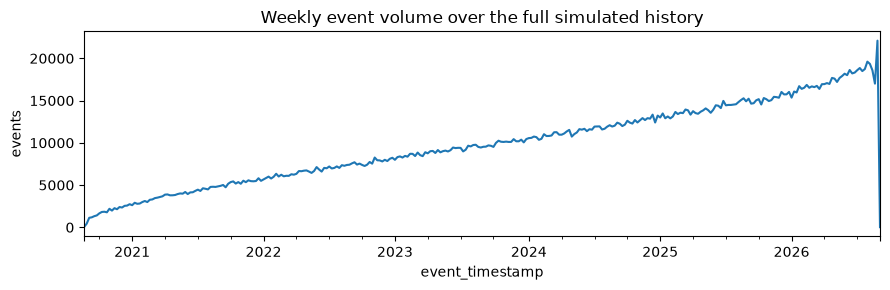


=== Final row counts ===
  users: 9,156
  subscriptions: 9,156
  payments: 227,990
  events: 3,086,822


In [11]:
# Retention sanity check: an OLD cohort must still have early-lifecycle events,
# or day-7/day-30 retention would silently read as zero for them.
old_user = raw.loc[raw['tenure'] >= 70, 'customerID'].iloc[0]
su = pd.Timestamp(users.loc[users.user_id == old_user, 'signup_date'].iloc[0])
early = events[(events.user_id == old_user) & (events.event_timestamp < su + pd.Timedelta(days=30))]
print(f"user {old_user} (tenure 70+ months, signed up {su.date()}): "
      f"{len(early)} events in their first 30 days -> retention math will work for this cohort")

# Funnel invariant: every paid user must be activated, or the funnel breaks
in_trial_features_check = events.loc[events['event_name'] == 'feature_used', ['user_id', 'event_timestamp']]
still_missing = paid_users[~paid_users['user_id'].isin(
    set(in_trial_features_check.merge(paid_users, on='user_id')
        .query('event_timestamp >= trial_start and event_timestamp < trial_end')['user_id'])
)]
assert len(still_missing) == 0, f"{len(still_missing)} paid users still have no in-trial activation event"
print("funnel invariant OK: every paid user has >=1 in-trial feature_used event")

weekly = events.set_index('event_timestamp').resample('W').size()
fig, ax = plt.subplots(figsize=(9, 3))
weekly.iloc[:-1].plot(ax=ax)   # drop the trailing partial week
ax.set_title('Weekly event volume over the full simulated history')
ax.set_ylabel('events')
plt.tight_layout()
plt.show()

print()
print("=== Final row counts ===")
for name, df in [('users', users), ('subscriptions', subscriptions), ('payments', payments), ('events', events)]:
    print(f"  {name}: {len(df):,}")


## Step 8 — Write processed CSVs

`data/processed/` is gitignored — `events.csv` alone lands around 200MB,
well past GitHub's 100MB push limit, and all four files are fully
reproducible by re-running this notebook against the real CSV in
`data/raw/`.


In [12]:
os.makedirs(OUT_DIR, exist_ok=True)
users.to_csv(f'{OUT_DIR}/users.csv', index=False)
subscriptions.to_csv(f'{OUT_DIR}/subscriptions.csv', index=False)
payments.to_csv(f'{OUT_DIR}/payments.csv', index=False)
events.to_csv(f'{OUT_DIR}/events.csv', index=False)

for f in ['users.csv', 'subscriptions.csv', 'payments.csv', 'events.csv']:
    print(f"  {f}: {os.path.getsize(f'{OUT_DIR}/{f}')/1_000_000:.1f} MB")


  users.csv: 0.4 MB
  subscriptions.csv: 0.4 MB
  payments.csv: 7.8 MB
  events.csv: 228.3 MB


## Step 9 — Load into Postgres

Uses `COPY` (via `psycopg2`'s `copy_expert`) rather than row-by-row inserts —
at 3M+ rows the difference is minutes vs. seconds. Truncating first makes this
notebook safe to re-run end-to-end.


In [13]:
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv('../.env')

db_url = (f"postgresql+psycopg2://{os.getenv('PGUSER')}:{os.getenv('PGPASSWORD', '')}"
          f"@{os.getenv('PGHOST', 'localhost')}:{os.getenv('PGPORT', '5432')}/{os.getenv('PGDATABASE')}")
engine = create_engine(db_url)

with engine.begin() as conn:
    conn.execute(text("TRUNCATE TABLE payments, events, subscriptions, users RESTART IDENTITY CASCADE;"))

def copy_csv(table, path):
    raw_conn = engine.raw_connection()
    try:
        cur = raw_conn.cursor()
        with open(path, 'r') as f:
            cur.copy_expert(f"COPY {table} FROM STDIN WITH (FORMAT csv, HEADER true)", f)
        raw_conn.commit()
    finally:
        raw_conn.close()

for table in ['users', 'subscriptions', 'payments', 'events']:  # parent before children
    copy_csv(table, f'{OUT_DIR}/{table}.csv')
    print(f"  loaded {table}")

with engine.begin() as conn:
    conn.execute(text(
        "SELECT setval(pg_get_serial_sequence('payments','payment_id'), "
        "COALESCE((SELECT MAX(payment_id) FROM payments), 1));"))
    conn.execute(text(
        "SELECT setval(pg_get_serial_sequence('events','event_id'), "
        "COALESCE((SELECT MAX(event_id) FROM events), 1));"))

print(f"\nDone in {time.time()-t0:.0f}s total")


  loaded users
  loaded subscriptions


  loaded payments


  loaded events

Done in 85s total


## Step 10 — Verify the load

In [14]:
display(pd.read_sql(text('''
    SELECT 'users' AS tbl, COUNT(*) AS n FROM users
    UNION ALL SELECT 'subscriptions', COUNT(*) FROM subscriptions
    UNION ALL SELECT 'payments', COUNT(*) FROM payments
    UNION ALL SELECT 'events', COUNT(*) FROM events
'''), engine))

display(pd.read_sql(text('''
    SELECT status, COUNT(*) AS users, COUNT(paid_date) AS converted
    FROM subscriptions GROUP BY status ORDER BY status
'''), engine))


,tbl,n
0,users,9156
1,subscriptions,9156
2,payments,227990
3,events,3086822


,status,users,converted
0,active,5174,5174
1,churned,3982,1869
